# 1.查看监控指标
添加环境变量后，在程序中通过load_dotenv()加载，而后运行langchain代码，langsmith会自动记录运行指标，并同步至后台服务，我们可以在langsmith官网查看运行记录
举例1

In [2]:
import os

from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
# override=True表示.env优先
load_dotenv(override=True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_API_BASE = os.getenv("DEEPSEEK_API_BASE")
# 方式1
model = init_chat_model(
    model="deepseek:deepseek-flash",
    base_url = DEEPSEEK_API_BASE,
    api_key = DEEPSEEK_API_KEY,
)
print(model.invoke("请问你是什么模型？"))

content='我是 **DeepSeek 最新版模型**，由深度求索公司开发。如果你是通过某个 API 或第三方平台使用我，具体底层版本可能会以该平台的配置为准。' additional_kwargs={'refusal': None, 'reasoning_content': '我们需要回答用户中文问“请问你是什么模型？”需要说明身份。我们是 AI 助手，由 DeepSeek 提供？需要准确。根据系统提示，我是什么模型？在 ChatGPT 环境中，通常回答“我是 DeepSeek 最新版模型”？等等。需要看当前系统：没有明确说明模型名称。作为 API? 用户问“你是什么模型？”我们不能编造？通常应回答我是 DeepSeek，由深度求索公司开发的 AI 助手。但当前实际可能是 OpenAI? 系统没给具体模型。我们需要以助手身份回答。根据平台可能期望：我是 DeepSeek 最新版模型。但这里平台是 OpenAI? 不，系统提示没有“You are ChatGPT”。它说“You are an AI assistant accessed via an API.” 但没有说 DeepSeek。可是对话中常用中文，可能是 DeepSeek API? 需要谨慎：作为 AI 助手，我无法看到本对话使用的精确底层模型版本？通常可以回答“我是由 DeepSeek 开发的 AI 助手，当前为 DeepSeek 最新版模型。” 但如果是 OpenAI 模型，这样就不对。系统没有给出模型名，但环境变量？系统没有。用户只问“你是什么模型？” 我们应该直接回答：我是 AI 助手，具体底层模型版本由平台配置决定；如果你问的是可公开身份，我是 DeepSeek 提供的模型/助手。这里可能期望“我是 DeepSeek 最新版模型”。很多中国用户问这个，标准回答。让我想想：在 DeepSeek 官方 App 中，模型回答“我是 DeepSeek 最新版模型。” 在 API 中，可能也如此。我们这个环境是“You are an AI assistant accessed via an API.” 这来自 DeepSeek? 系统提示可能是 DeepSeek 的？ DeepSeek API 的系统提示? 通常 DeepSeek 没有固定身份。很多 benchmark 里会问“你是什么模型？” 答

举例2

In [9]:
load_dotenv(override=True)

ARK_API_BASE = os.getenv("ARK_API_BASE")
ARK_API_KEY = os.getenv("ARK_API_KEY")

model = init_chat_model(
    model="glm-5-2-260617",
    model_provider="openai",
    base_url = ARK_API_BASE,
    api_key = ARK_API_KEY,
)

print(model.invoke("你是什么模型"))

content='我是Z.ai开发的GLM大语言模型。我通过大规模文本数据训练，能够理解和生成人类语言，回答问题并提供信息。\n\nZ.ai持续优化我的能力，使我能够进行对话、创作内容和辅助解决问题，同时我也在不断学习和进步。\n\n有什么具体的问题或任务我可以帮您解答吗？' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 263, 'prompt_tokens': 15, 'total_tokens': 278, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 200, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'glm-5-2-260617', 'system_fingerprint': None, 'id': '021790733002044534779bc6a83ab3f36a7a90c1e71ba35ee62bf', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a0f001-233a-7871-8439-eb16d16de9e4-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 15, 'output_tokens': 263, 'total_tokens': 278, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 200}}


举例3
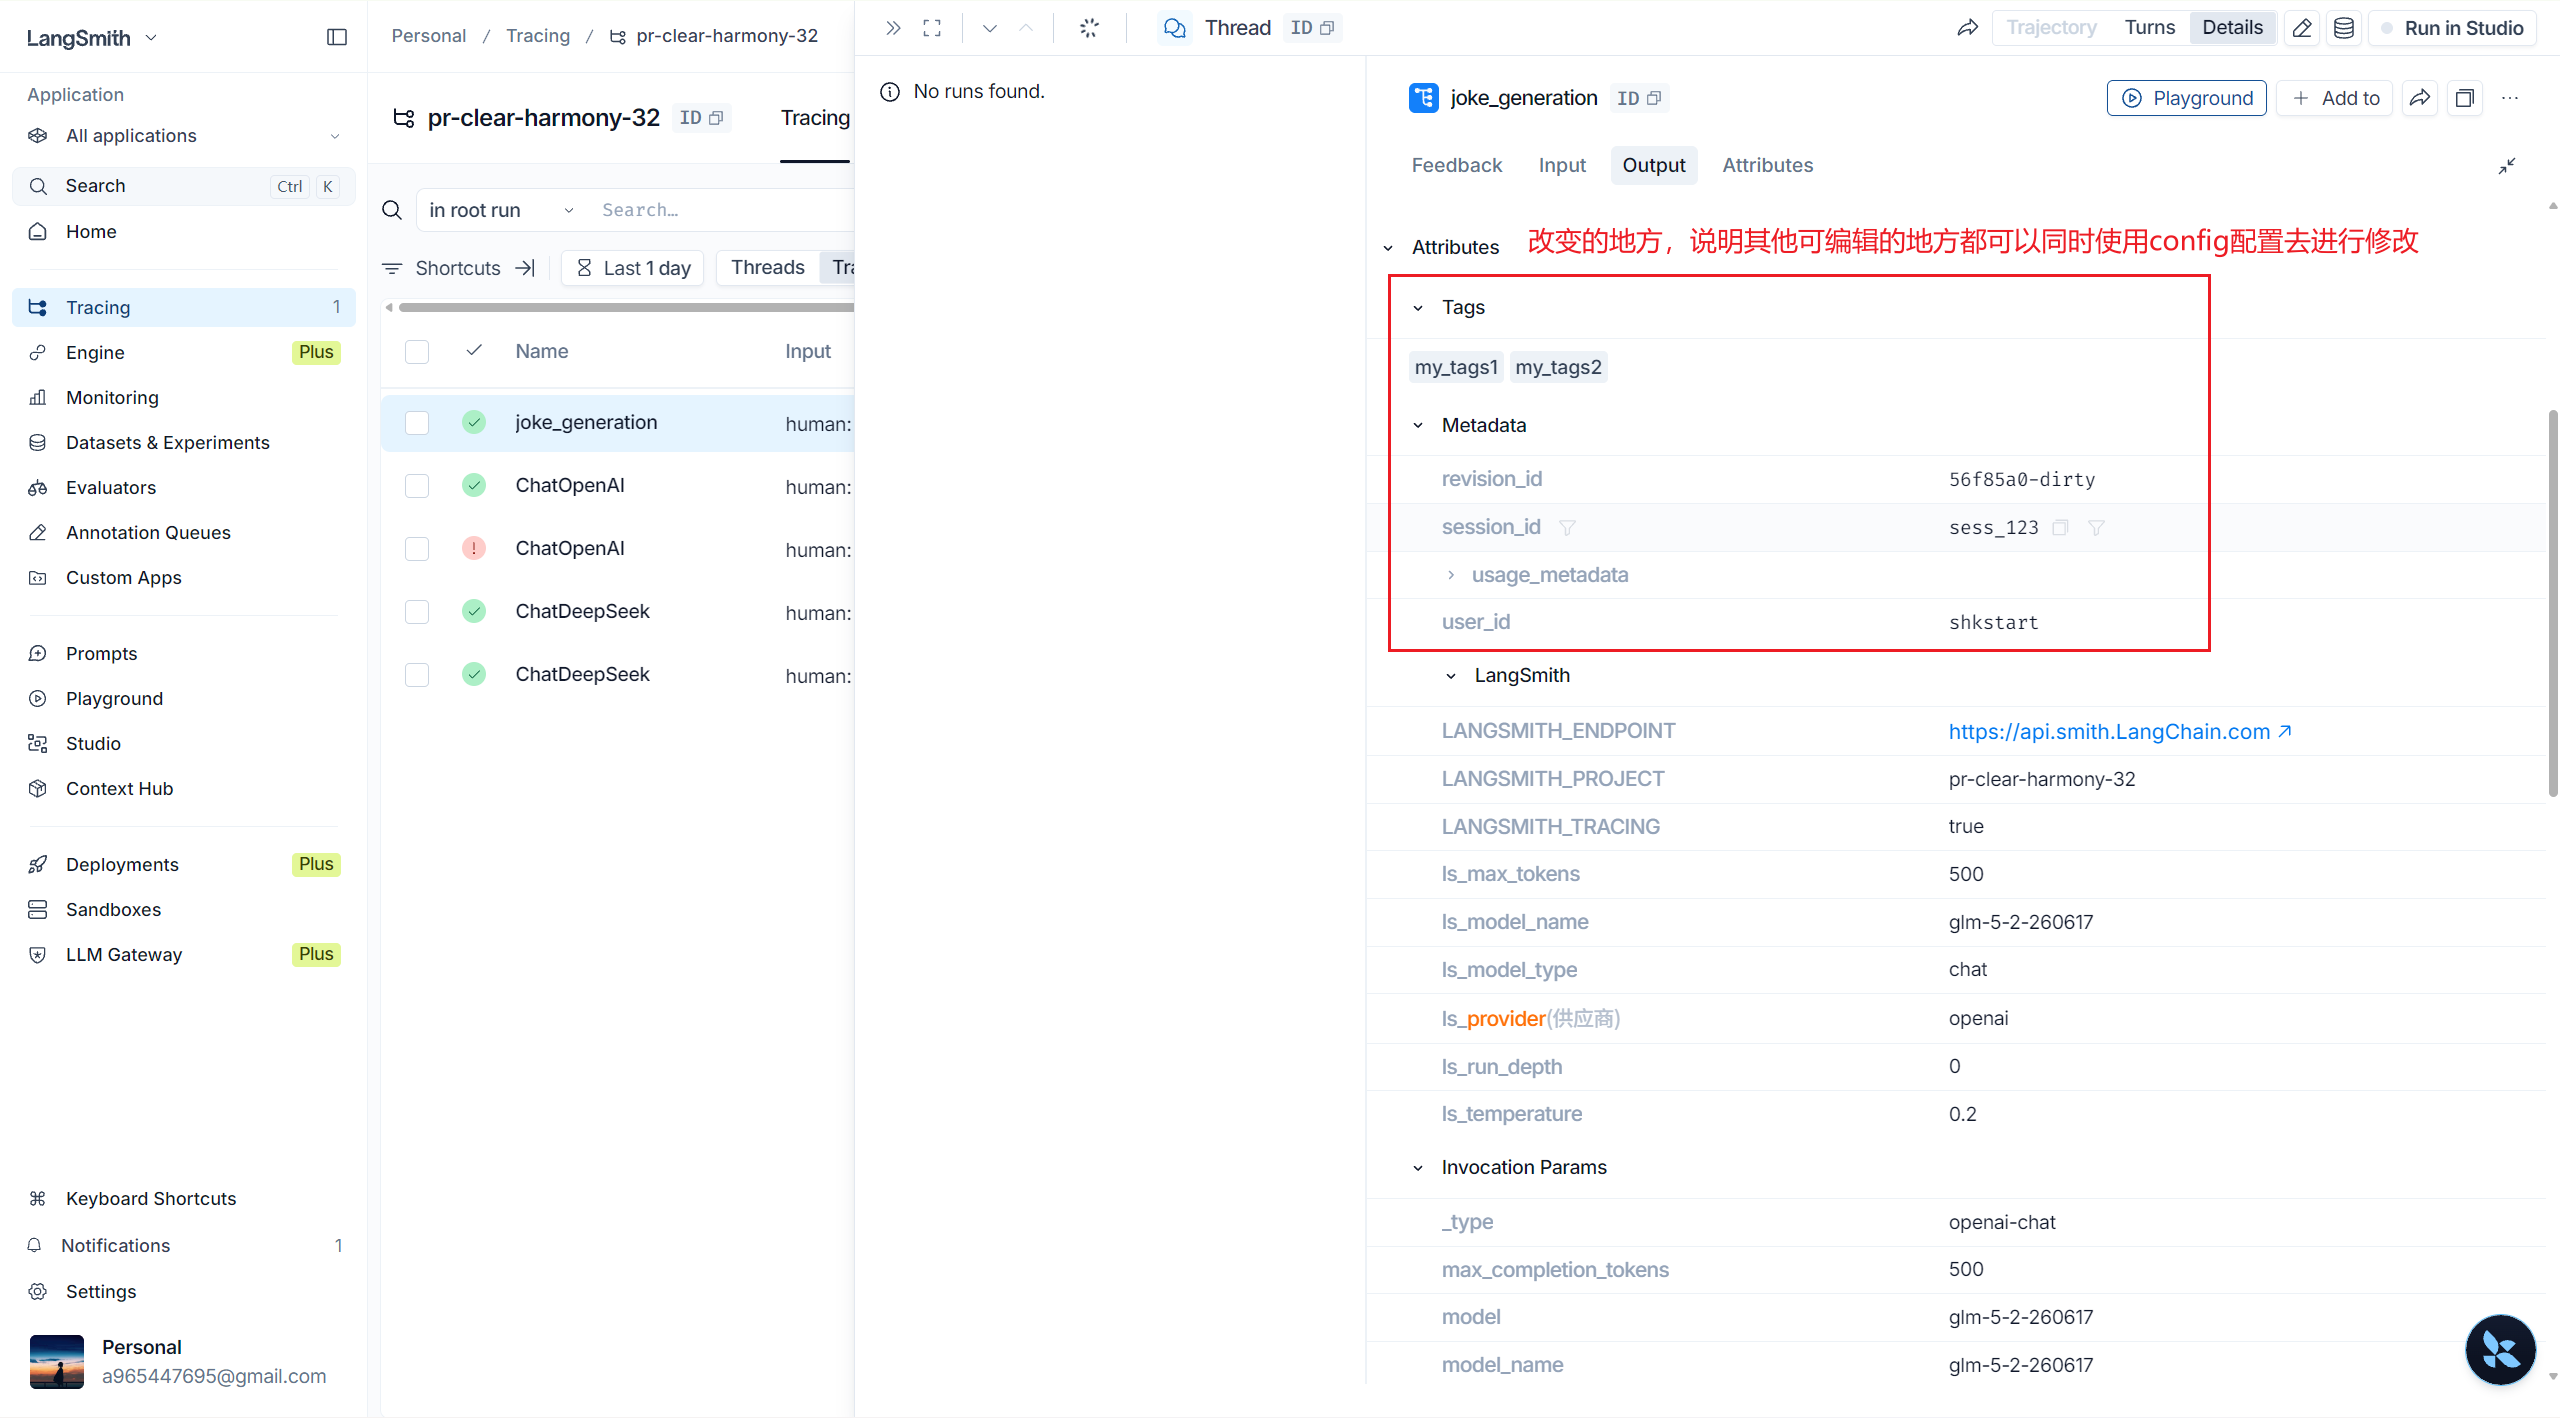

In [10]:
load_dotenv(override=True)

ARK_API_BASE = os.getenv("ARK_API_BASE")
ARK_API_KEY = os.getenv("ARK_API_KEY")

model = init_chat_model(
    model="glm-5-2-260617",
    model_provider="openai",
    base_url = ARK_API_BASE,
    api_key = ARK_API_KEY,
    temperature = 0.2,
    max_tokens = 500,
    # 指定可调整参数
    configurable_fields=(
        "temperature",
        "max_tokens",
        "model",
        "model_provider",
    ),
)
# 2.准备 conifg 字典
config = {
    "run_name":"joke_generation", # 在langsmith中这次运行会显示为"joke_generation"
    "tags":["my_tags1","my_tags2"], # 打上标签便于分类查找
    "metadata":{
        "user_id":"shkstart", # 记录用户ID
        "session_id":"sess_123" # 记录会话id
    },
}
# 3. 调用模型并传入config
response = model.invoke(
    "1 + 2 = ?",
    config = config,
)

print(response)

content='3' additional_kwargs={'refusal': None} response_metadata={'token_usage': {'completion_tokens': 86, 'prompt_tokens': 18, 'total_tokens': 104, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 85, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'glm-5-2-260617', 'system_fingerprint': None, 'id': '02179073333835891be90b70b1bfc3059428bd07e108b7eb60f38', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a0f006-44f3-7ad2-ac5d-c0d2e874399d-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 18, 'output_tokens': 86, 'total_tokens': 104, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 85}}
